# Choosing What to Notice

*The Mathematics of Machine Intelligence · Chapter 5*

Share out a limited budget of attention with softmax and divisive normalization, and see what the weights cannot say.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what is being weighed, what each score or drive is, whether anything can give weight to nothing, and who supplies the gain: a cue or goal in the cortex models, the model's own comparison in a transformer. Use the softmax card for shares of a budget of one, the spare-slot card to see what changes when 'none of these' is allowed, the normalization card for gains and a constant, and the reported-result cards for position and look-alike effects. Say that a weight is a share, not a probability of truth.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 5, Choosing What to Notice: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def fmt2(value):
    """Two decimals, for the chapter's firing rates."""
    return f'{float(value):.2f}'

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def softmax_weights(scores, spare_slot=False):
    """alpha_j = exp(s_j) / (sum_k exp(s_k) [+ 1 for the spare slot, which is exp(0)])."""
    e = np.exp(np.asarray(scores, dtype=float))
    return e / (e.sum() + (1.0 if spare_slot else 0.0))

def gain_outputs(gains, signals=None):
    """Turning down is a multiplier from 0 to 1 on each stream's own signal."""
    gains = np.asarray(gains, dtype=float)
    if np.any(gains < 0) or np.any(gains > 1):
        raise ValueError('A gain used to turn a stream down must lie between 0 and 1.')
    signals = np.ones_like(gains) if signals is None else np.asarray(signals, dtype=float)
    return gains * signals

def softmax_turn_down(ignored_gain, n_ignored):
    """Shares when each ignored stream's weight is scaled by ignored_gain inside a softmax with equal base scores.

    Scaling a weight exp(s) by g means lowering its score by ln(1/g); the attended stream's score is untouched.
    """
    if not 0 < ignored_gain <= 1:
        raise ValueError('Use a gain above 0 and at most 1; a gain of exactly 0 is the limit of an infinitely low score.')
    scores = np.concatenate([[0.0], np.full(n_ignored, math.log(ignored_gain))])
    return softmax_weights(scores)
IGNORED_GAINS = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
IGNORED_COUNTS = [1, 3]

def turn_down_picture(ignored_gain=0.25, n_ignored=1):
    g_out = gain_outputs([1.0] + [ignored_gain] * n_ignored)
    if ignored_gain > 0:
        shares = softmax_turn_down(ignored_gain, n_ignored)
    else:
        shares = np.array([1.0] + [0.0] * n_ignored)
    fig, ax = panels()
    width = 0.34
    ax[0].bar([0 - width / 2, 1 - width / 2], [g_out[0], shares[0]], width=width, color=TEAL, label='attended stream')
    ax[0].bar([0 + width / 2, 1 + width / 2], [g_out[1], shares[1]], width=width, color=GOLD, label='each ignored stream')
    for x, v in [(0 - width / 2, g_out[0]), (1 - width / 2, shares[0]), (0 + width / 2, g_out[1]), (1 + width / 2, shares[1])]:
        tag(ax[0], x, v + 0.03, sig(v), fontsize=10, va='bottom')
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['turned down by a gain\n(signal passed)', 'shares of one budget\n(softmax weights)'], fontsize=9)
    ax[0].set(ylim=(0, 1.25), ylabel='signal or weight', title=f'Ignored gain {ignored_gain:g}, {n_ignored} ignored')
    ax[0].legend(fontsize=8, loc='upper right')
    grid = np.linspace(0.02, 1, 100)
    ax[1].plot(grid, np.ones_like(grid), color=GREY, linestyle='dashed', linewidth=1.6, label='gain: attended stream unchanged')
    for n, col in zip(IGNORED_COUNTS, [NAVY, TERRA]):
        ax[1].plot(grid, [1 / (1 + n * g) for g in grid], color=col, linewidth=2.6 if n == n_ignored else 1.3, label=f'softmax, {n} ignored')
    ring(ax[1], max(ignored_gain, 0.02), shares[0])
    ax[1].set(xlabel='gain on each ignored stream', ylabel="attended stream's weight", ylim=(0, 1.1), title='Softmax pays by raising the attended share')
    ax[1].legend(fontsize=8, loc='lower left')
    ignored_total = float(shares[1:].sum())
    metrics = {'Attended, gain model': sig(g_out[0]), 'Each ignored, gain model': sig(g_out[1]), 'Attended share, softmax': sig(shares[0]), 'Ignored total share, softmax': sig(ignored_total)}
    summary = f"A gain of {ignored_gain:g} makes each ignored stream quieter but leaves the attended stream at 1. In a softmax the shares must add to 1, so shrinking {n_ignored} ignored stream{('s' if n_ignored > 1 else '')} lifts the attended share to {sig(shares[0])}."
    calc = f'Softmax with scores 0 and ln({ignored_gain:g}) for each ignored stream: attended share = 1 / (1 + {n_ignored} x {ignored_gain:g}) = {sig(1 / (1 + n_ignored * ignored_gain))}.' if ignored_gain > 0 else 'A gain of exactly 0 removes the ignored streams; the attended share is 1.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SCORES = [-6, -4, -3, -2, -1, 0, 1, 2]
TOKEN_COUNTS = [4, 20]

def spare_slot_picture(score=-3, n_tokens=4):
    scores = np.full(n_tokens, float(score))
    plain = softmax_weights(scores)
    spare = softmax_weights(scores, spare_slot=True)
    total_spare = float(spare.sum())
    fig, ax = panels()
    vals = [plain[0], spare[0], 1 - total_spare]
    bars = ax[0].bar(range(3), vals, color=[TEAL, GOLD, GREY], width=0.6)
    for b, v in zip(bars, vals):
        tag(ax[0], b.get_x() + b.get_width() / 2, v + 0.02, sig(v), fontsize=10, va='bottom')
    ax[0].set_xticks(range(3))
    ax[0].set_xticklabels(['each token,\nplain softmax', 'each token,\nspare slot', 'left for the\nspare slot'], fontsize=9)
    ax[0].set(ylim=(0, 1.0), ylabel='weight', title=f'{n_tokens} tokens, each scoring {score}')
    grid = np.linspace(-6, 2, 200)
    ax[1].plot(grid, np.ones_like(grid), color=TEAL, linewidth=2.4, label='plain softmax')
    for n, col in zip(TOKEN_COUNTS, [NAVY, TERRA]):
        ax[1].plot(grid, n * np.exp(grid) / (1 + n * np.exp(grid)), color=col, linewidth=2.6 if n == n_tokens else 1.3, label=f'spare slot, {n} tokens')
    ring(ax[1], score, total_spare)
    ax[1].set(xlabel='score shared by every token', ylabel='total weight handed out', ylim=(0, 1.12), title="Only the spare slot can say 'none of these'")
    ax[1].legend(fontsize=8, loc='lower right')
    metrics = {'Each token, plain': sig(plain[0]), 'Each token, spare slot': sig(spare[0]), 'Total, plain': sig(plain.sum()), 'Total, spare slot': sig(total_spare)}
    summary = f'Plain softmax gives each of {n_tokens} equal-scoring tokens {sig(plain[0])} and always hands out a total of 1, whatever the score. With a spare slot each gets {sig(spare[0])} and the total is {sig(total_spare)}, which falls as the common score falls.'
    calc = f'Plain: 1 / {n_tokens} = {sig(plain[0])}. Spare slot: e^({score}) / (1 + {n_tokens} e^({score})) = {sig(spare[0])}; total = {n_tokens} x {sig(spare[0])} = {sig(total_spare)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def normalized_responses(drives, gains, sigma):
    """R_i = g_i d_i / (sigma + sum_j g_j d_j)."""
    d, g = (np.asarray(drives, dtype=float), np.asarray(gains, dtype=float))
    if np.any(d < 0) or np.any(g < 0):
        raise ValueError('Drives and gains must be nonnegative.')
    if sigma < 0:
        raise ValueError('The constant sigma must not be negative.')
    total = sigma + np.sum(g * d)
    if total <= 0:
        raise ValueError('Undefined: the denominator is zero when sigma is zero and every boosted drive is zero.')
    return g * d / total
DRIVES = [4.0, 1.0]
ATTENTION_GAINS = [1, 2, 3, 4, 6, 8]
SIGMAS = [0, 1, 4]

def normalization_picture(gain=4, sigma=1):
    base = normalized_responses(DRIVES, [1, 1], sigma)
    att = normalized_responses(DRIVES, [1, gain], sigma)
    fig, ax = panels()
    x = np.arange(2)
    ax[0].bar(x - 0.19, base, width=0.36, color=GREY, label='no attention')
    ax[0].bar(x + 0.19, att, width=0.36, color=TEAL, label=f'gain {gain:g} on input 2')
    for xi, v in zip(x - 0.19, base):
        tag(ax[0], xi, v + 0.02, sig(v), fontsize=9, va='bottom')
    for xi, v in zip(x + 0.19, att):
        tag(ax[0], xi, v + 0.02, sig(v), fontsize=9, va='bottom')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(['input 1\n(drive 4)', 'input 2\n(drive 1)'])
    ax[0].set(ylim=(0, 1.1), ylabel='response', title=f'Constant sigma = {sigma:g}')
    ax[0].legend(fontsize=8, loc='upper right')
    grid = np.linspace(1, 8, 100)
    r1 = [normalized_responses(DRIVES, [1, g], sigma)[0] for g in grid]
    r2 = [normalized_responses(DRIVES, [1, g], sigma)[1] for g in grid]
    ax[1].plot(grid, r1, color=NAVY, label='input 1 (unattended)')
    ax[1].plot(grid, r2, color=GOLD, label='input 2 (attended)')
    ring(ax[1], gain, att[0])
    ring(ax[1], gain, att[1])
    ax[1].set(xlabel='attention gain on input 2', ylabel='response', ylim=(0, 1.05), title='The attended input rises, its rival falls')
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {'Response, input 1': sig(att[0]), 'Response, input 2': sig(att[1]), 'Sum of responses': sig(att.sum()), 'Input 1 with no attention': sig(base[0])}
    summary = f"With drives 4 and 1, constant {sigma:g} and a gain of {gain:g} on input 2, the responses are {sig(att[0])} and {sig(att[1])}, against {sig(base[0])} and {sig(base[1])} with no attention. {('With sigma 0 the responses always add to 1, the softmax limit.' if sigma == 0 else 'The constant keeps the total below 1 and lets weak inputs stay weak.')}"
    calc = f'Denominator = {sig(sigma)} + 4 + {gain:g} x 1 = {sig(sigma + 4 + gain)}. R1 = 4 / {sig(sigma + 4 + gain)} = {sig(att[0])}; R2 = {gain:g} / {sig(sigma + 4 + gain)} = {sig(att[1])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
R_FIRST, R_SECOND, R_PAIR = (11.75, 17.8, 13.81)
POOLED_WEIGHTS = {'attention on the first bar': 0.34, 'attention elsewhere': 0.55, 'attention on the second bar': 0.74}

def pair_response(weight_second, r_first=R_FIRST, r_second=R_SECOND):
    """The pair's response as a weighted average of the two single-bar responses (the fitted model can also have an offset)."""
    if not 0 <= weight_second <= 1:
        raise ValueError('The weight on the second bar must lie between 0 and 1.')
    return (1 - weight_second) * r_first + weight_second * r_second

def weight_from_pair(r_first=R_FIRST, r_second=R_SECOND, r_pair=R_PAIR):
    if r_second == r_first:
        raise ValueError('Undefined: the two single-bar responses are equal, so the weight cannot be read from the pair.')
    return (r_pair - r_first) / (r_second - r_first)

def implied_gain_ratio(weight, baseline_weight=0.55):
    """Gain on the second bar relative to its value at baseline, if the weight is the share g2 d2 / (g1 d1 + g2 d2)."""
    if not 0 < weight < 1:
        raise ValueError('The weight must lie strictly between 0 and 1 for a share to be inverted.')
    return weight / (1 - weight) / (baseline_weight / (1 - baseline_weight))
WEIGHT_CHOICES = [0.0, 0.34, 0.55, 0.74, 1.0]

def weighted_average_picture(weight=0.55):
    resp = pair_response(weight)
    own = weight_from_pair()
    fig, ax = panels()
    ax[0].plot([R_FIRST, R_SECOND], [0, 0], color=GREY, linewidth=1.5, zorder=1)
    ax[0].plot([R_FIRST], [0], marker='o', markersize=13, color=NAVY)
    ax[0].plot([R_SECOND], [0], marker='o', markersize=13, color=GOLD)
    ax[0].plot([resp], [0], marker='D', markersize=12, color=TEAL, zorder=5)
    tag(ax[0], R_FIRST, 0.3, f'first bar alone\n{fmt2(R_FIRST)}', fontsize=9)
    tag(ax[0], R_SECOND, 0.3, f'second bar alone\n{fmt2(R_SECOND)}', fontsize=9)
    tag(ax[0], resp, -0.3, f'pair, weight {weight:g}\n{fmt2(resp)} spikes/s', fontsize=10, color=TEAL, va='top')
    ax[0].plot([R_PAIR], [-0.75], marker='v', markersize=11, color=TERRA)
    tag(ax[0], R_PAIR, -0.98, f"this cell's reported pair, {fmt2(R_PAIR)}", fontsize=8, va='top', color=TERRA)
    ax[0].set(xlim=(10.5, 19.2), ylim=(-1.3, 0.85), yticks=[], xlabel='firing rate (spikes per second)', title="One cell's responses and the weighted average")
    ax[0].spines['left'].set_visible(False)
    ws = np.linspace(0, 1, 50)
    ax[1].plot(ws, [pair_response(w) for w in ws], color=NAVY, linewidth=2)
    for name, w in POOLED_WEIGHTS.items():
        ax[1].plot([w], [pair_response(w)], marker='s', color=DARK_GOLD, markersize=7, linestyle='none')
    tag(ax[1], 0.34, pair_response(0.34) + 0.9, '0.34', fontsize=8, color=DARK_GOLD)
    tag(ax[1], 0.55, pair_response(0.55) - 0.9, '0.55', fontsize=8, color=DARK_GOLD)
    tag(ax[1], 0.74, pair_response(0.74) + 0.9, '0.74', fontsize=8, color=DARK_GOLD)
    ax[1].plot([own], [R_PAIR], marker='v', color=TERRA, markersize=9, linestyle='none')
    ring(ax[1], weight, resp)
    ax[1].set(xlabel='weight on the second bar', ylabel='pair response (spikes/s)', title='Squares: pooled V4 fits', ylim=(10.5, 19.2))
    metrics = {'Pair response': fmt2(resp), 'Weight on second bar': sig(weight), "This cell's own weight": sig(own)}
    if 0 < weight < 1:
        metrics['Implied gain ratio'] = sig(implied_gain_ratio(weight))
    summary = f'A weight of {weight:g} on the second bar puts the pair at {fmt2(resp)} spikes a second, between {fmt2(R_FIRST)} and {fmt2(R_SECOND)}. The cell in the chapter fired {fmt2(R_PAIR)}, a weight of {sig(own)}, about a third of the way.'
    calc = f'Pair = (1 - {weight:g}) x {fmt2(R_FIRST)} + {weight:g} x {fmt2(R_SECOND)} = {fmt2(resp)}. This cell: ({fmt2(R_PAIR)} - {fmt2(R_FIRST)}) / ({fmt2(R_SECOND)} - {fmt2(R_FIRST)}) = {sig(own)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
POOL = 8

def attended_response(contrast, gain, covered, pool=POOL, sigma=1.0):
    """Response of an attended unit when `covered` of `pool` equally driven units (itself included) get the attention gain.

    R = g c / (sigma + c (covered g + (pool - covered))). Covering the whole pool rescales contrast;
    covering only the unit itself raises the ceiling.
    """
    if not 1 <= covered <= pool:
        raise ValueError('The attended unit itself must be covered, and no more units than the pool can be.')
    return gain * contrast / (sigma + contrast * (covered * gain + (pool - covered)))

def ceiling_and_half_point(gain, covered, pool=POOL, sigma=1.0):
    """Top response (very high contrast) and the contrast giving half of it."""
    a = covered * gain + (pool - covered)
    return (gain / a, sigma / a)
COVERED_UNITS = [1, 4, 8]
GAIN_VALUES = [1, 1.5, 2, 3, 4, 6]

def gain_regime_picture(gain=4, covered=1):
    ceil_a, half_a = ceiling_and_half_point(gain, covered)
    ceil_0, half_0 = ceiling_and_half_point(1, covered)
    fig, ax = panels()
    c = np.logspace(-2.5, 2.5, 300)
    ax[0].plot(c, attended_response(c, 1, covered), color=GREY, linewidth=2, label='no attention')
    ax[0].plot(c, attended_response(c, gain, covered), color=TEAL, linewidth=2.6, label=f'attention gain {gain:g}')
    ax[0].set(xscale='log', xlabel='stimulus contrast (units of sigma)', ylabel='response', ylim=(0, 0.46), title=f'Attention covers {covered} of {POOL} pooled units')
    ax[0].legend(fontsize=8, loc='upper left')
    grid = np.linspace(1, 6, 60)
    colours = {1: TERRA, 4: GOLD, 8: NAVY}
    for k in COVERED_UNITS:
        lw = 2.6 if k == covered else 1.2
        ax[1].plot(grid, [ceiling_and_half_point(g, k)[0] / ceiling_and_half_point(1, k)[0] for g in grid], color=colours[k], linewidth=lw, label=f'covers {k}')
        ax[1].plot(grid, [ceiling_and_half_point(1, k)[1] / ceiling_and_half_point(g, k)[1] for g in grid], color=colours[k], linewidth=lw, linestyle='dashed')
    ring(ax[1], gain, ceil_a / ceil_0)
    ax[1].set(xlabel='attention gain', ylabel='factor against no attention', title='Solid: ceiling. Dashed: sensitivity', ylim=(0.8, 6.3))
    ax[1].legend(fontsize=8, loc='upper left')
    metrics = {'Ceiling with attention': sig(ceil_a), 'Ceiling without': sig(ceil_0), 'Ceiling factor': sig(ceil_a / ceil_0), 'Sensitivity factor': sig(half_0 / half_a)}
    if gain == 1:
        kind = 'no change, since there is no attention gain'
    elif abs(ceil_a / ceil_0 - 1) < 1e-09:
        kind = 'a change in sensitivity only (contrast gain)'
    elif covered == 1:
        kind = 'a raised ceiling with a smaller sensitivity change (response gain)'
    else:
        kind = 'a mix of the two'
    summary = f'With the attention gain {gain:g} covering {covered} of {POOL} pooled units, the ceiling goes from {sig(ceil_0)} to {sig(ceil_a)} and the sensitivity improves by a factor of {sig(half_0 / half_a)}. That is {kind}.'
    calc = f'R = g c / (1 + c (k g + {POOL} - k)) with k = {covered}. Ceiling = g / (k g + {POOL} - k) = {sig(ceil_a)}; half-response contrast = 1 / (k g + {POOL} - k) = {sig(half_a)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def answer_share(gap, n_distractors):
    """Share of the answer passage when it scores `gap` above each of n equal distractors: 1 / (1 + n exp(-gap))."""
    return 1.0 / (1.0 + n_distractors * math.exp(-gap))
GAPS = [0, 1, 2, 3, 4, 6]
DISTRACTOR_COUNTS = [8, 19]

def lookalike_picture(gap=2, n_distractors=8):
    share = answer_share(gap, n_distractors)
    fig, ax = panels()
    ax[0].bar([0, 1], [share, 1 - share], color=[TEAL, GOLD], width=0.55)
    tag(ax[0], 0, share + 0.03, sig(share), fontsize=11, va='bottom')
    tag(ax[0], 1, 1 - share + 0.03, sig(1 - share), fontsize=11, va='bottom')
    ax[0].axhline(1 / (n_distractors + 1), color=GREY, linestyle='dashed', linewidth=1.2)
    tag(ax[0], -0.4, 1 / (n_distractors + 1), 'tie share', fontsize=8, ha='left', va='bottom', color=GREY)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['answer passage', f'all {n_distractors} others\ncombined'])
    ax[0].set(ylim=(0, 1.1), ylabel='share of the weight', title=f'Answer scores {gap:g} above each other passage')
    grid = np.linspace(0, 6, 120)
    for n, col in zip(DISTRACTOR_COUNTS, [NAVY, TERRA]):
        ax[1].plot(grid, [answer_share(g, n) for g in grid], color=col, linewidth=2.6 if n == n_distractors else 1.3, label=f'{n} other passages')
    ring(ax[1], gap, share)
    ax[1].axvline(0, color=GREY, linewidth=0.8)
    ax[1].set(xlabel='score gap: answer minus each other passage', ylabel="answer's share", ylim=(0, 1.05), title='Look-alikes sit near gap 0')
    ax[1].legend(fontsize=8, loc='lower right')
    metrics = {"Answer passage's share": sig(share), "Others' combined share": sig(1 - share), 'Share if all tie': sig(1 / (n_distractors + 1)), 'Each other passage': sig((1 - share) / n_distractors)}
    summary = f'With {n_distractors} other passages each scoring {gap:g} below the answer, the answer takes {sig(share)} of the weight and the others {sig(1 - share)} together. A look-alike near gap 0 takes nearly as large a share as the answer; one far below takes almost none. This is softmax arithmetic, not a test of why models failed.'
    calc = f'Answer share = 1 / (1 + {n_distractors} x e^(-{gap:g})) = 1 / (1 + {sig(n_distractors * math.exp(-gap))}) = {sig(share)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
POSITIONS = [1, 5, 10, 15, 20]
ACCURACY = {1: 75.8, 5: 57.2, 10: 53.8, 15: 55.4, 20: 63.2}
CLOSED_BOOK = 56.1
QUESTIONS = 2655

def rough_band(accuracy_percent, n=QUESTIONS, z=1.96):
    """Plus or minus z standard errors, in points, treating the score as the share correct among n independent questions."""
    p = accuracy_percent / 100.0
    return 100.0 * z * math.sqrt(p * (1 - p) / n)

def lost_in_middle_picture(position=10, band='show'):
    acc = ACCURACY[position]
    gap = acc - CLOSED_BOOK
    half = rough_band(CLOSED_BOOK)
    fig, ax = panels()
    xs = list(ACCURACY)
    ax[0].plot(xs, [ACCURACY[p] for p in xs], color=NAVY, marker='o', markersize=6, linewidth=2)
    ax[0].axhline(CLOSED_BOOK, color=TERRA, linestyle='dashed', linewidth=1.5)
    tag(ax[0], 19.7, CLOSED_BOOK - 1.0, f'no passages\n{sig(CLOSED_BOOK)}', fontsize=8, ha='right', va='top', color=TERRA)
    ring(ax[0], position, acc)
    ax[0].set(xlabel='position of the answer passage among 20', ylabel='questions answered correctly (percent)', xticks=xs, ylim=(48, 80), title='Five positions were tested')
    gaps = [ACCURACY[p] - CLOSED_BOOK for p in xs]
    ax[1].bar(range(5), gaps, color=[TEAL if g >= 0 else GOLD for g in gaps], width=0.6)
    if band == 'show':
        ax[1].axhspan(-half, half, color=GREY, alpha=0.22)
        tag(ax[1], 2, half + 0.5, 'rough noise band', fontsize=8, va='bottom', color=GREY)
    ax[1].axhline(0, color=GREY, linewidth=0.8)
    ax[1].set_xticks(range(5))
    ax[1].set_xticklabels([str(p) for p in xs])
    ring(ax[1], xs.index(position), gap)
    ax[1].set(xlabel='position of the answer passage', ylabel='points above the no-passage score', title='Gap to the no-passage score', ylim=(-6, 22))
    inside = abs(gap) <= half
    metrics = {'Accuracy at this position': f'{sig(acc)} percent', 'Points above no passages': sig(gap), 'Rough noise band (plus or minus)': sig(half), 'Gap outside the rough band': 'no' if inside else 'yes'}
    summary = f"With the answer at position {position}, the model answered {sig(acc)} percent, {sig(abs(gap))} points {('above' if gap >= 0 else 'below')} its no-passage score of {sig(CLOSED_BOOK)}. Only five positions were tested, so the curve between them is unknown, and the study measured answers, not attention weights."
    calc = f'Gap = {sig(acc)} - {sig(CLOSED_BOOK)} = {sig(gap)} points. Rough band = 1.96 x sqrt(p(1 - p) / 2,655) x 100 = plus or minus {sig(half)} points for p = 0.561, ignoring that the same questions were used every time.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C05-D01: Is turning a stream down the same as dividing a budget?

If an ignored stream is turned down by a gain, what happens to the attended stream, and what happens when a softmax does the shrinking?

A gain acts on one stream at a time. A softmax acts on all the streams together because its denominator is the total of every stream's exponential. Lowering one score therefore moves weight to the others, and with more ignored streams the attended stream's share at the same gain is smaller.

$$
y_i=g_i\,s_i\ \ (0\le g_i\le 1),\qquad \alpha_j=\frac{e^{s_j}}{\sum_k e^{s_k}}
$$

**Symbols:** g_i: a gain, a multiplier between 0 and 1 on stream i's own signal; s_i: the stream's signal in the gain model; its score in the softmax; alpha_j: weight of position j, a share of one whole; n: number of ignored streams (1 or 3 here)

**Predict before looking:** Two streams start with equal weight. Predict the attended stream's weight when the ignored stream is turned down to 0.25, under a gain and under a softmax whose weights must add to 1.

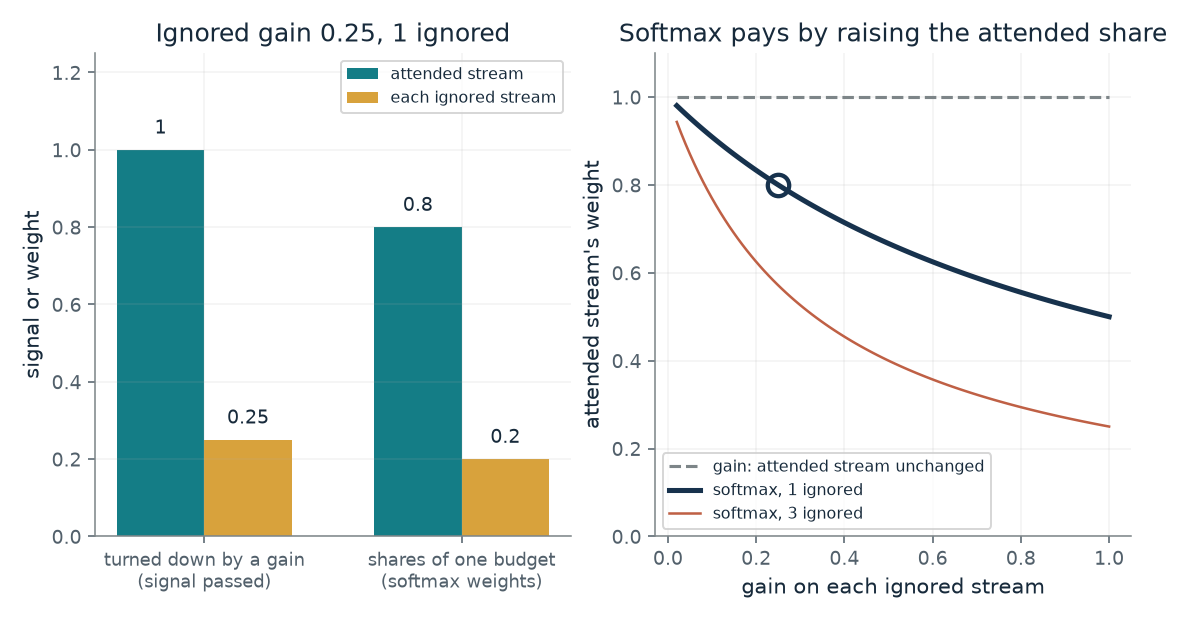

- **Attended, gain model:** 1
- **Each ignored, gain model:** 0.25
- **Attended share, softmax:** 0.8
- **Ignored total share, softmax:** 0.2

A gain of 0.25 makes each ignored stream quieter but leaves the attended stream at 1. In a softmax the shares must add to 1, so shrinking 1 ignored stream lifts the attended share to 0.8.

Softmax with scores 0 and ln(0.25) for each ignored stream: attended share = 1 / (1 + 1 x 0.25) = 0.8.

In [2]:
figure, values, explanation = turn_down_picture(**{'ignored_gain': 0.25, 'n_ignored': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Is turning a stream down the same as dividing a budget?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Gain on each ignored stream = 0.25, Number of ignored streams = 1: Under a gain the attended stream stays at 1 and the ignored one drops to 0.25. Under a softmax the shares must add to 1, so the attended stream rises to 0.8 and the ignored one falls to 0.2. Raise the number of ignored streams to 3 and the attended share at the same gain falls to 0.571.

**Takeaway:** A gain quiets one stream and leaves the others alone; a softmax can shrink one share only by raising another's.

**Why it matters:** Whether selecting something means turning the rest down or dividing a fixed budget changes what the attended stream receives. The chapter's later models differ on exactly this point.

**In brains and behavior:** In Treisman's task two passages swapped ears partway through. A filter that blocked the ignored ear completely would predict no slips, and 15 of 18 listeners made at least one. The abstract reads this as a raised threshold, but the paper allows other accounts, such as occasional sampling of the ignored ear. It is one small laboratory study.

**In machines:** For a machine, turning something down is easy: multiply a stream by a number between 0 and 1. Nothing in these studies says a brain does it that way.

**Where it applies:** Equal starting scores for all streams, a gain applied to a stream's own signal in one model and to its weight inside a softmax in the other. A trained attention head is far more complicated than a few scores, and no study here shows how a brain turns a stream down.

**Check your understanding:** Two streams have equal scores. Under a softmax, what weight does the attended stream get when the ignored stream's weight is scaled by 0.5? What does it get under a gain of 0.5 on the ignored stream?

<details><summary>Show the answer</summary>

1 / (1 + 0.5) = 0.667 under the softmax. Under the gain it stays at 1 and the ignored stream's signal is 0.5.

</details>

*Source: Chapter 5, Listeners missed a switch to German, and the ignored ear may be turned down. The chapter's sentence that multiplying a stream by a number between 0 and 1 quiets it while a softmax can shrink one share only by raising another's. The scores and gains are made up. Scaling a weight by g is the same as lowering its score by ln(1/g), which is the companion's construction. Treisman's 1960 study had 18 listeners, 15 of whom made at least one wrong-ear slip.*

## C05-D02: What changes when a head gets a spare slot?

If every available score is poor, can the weights say so, with plain softmax and with a spare slot?

Softmax divides each exponential by the total of all of them, so the shares add to one by construction. A spare slot adds one more term to the total that no token gets. When the token scores are low their exponentials are small next to that 1, so the slot takes most of the weight and the tokens share the rest.

$$
\alpha_j=\frac{e^{s_j}}{\sum_{k=1}^{n}e^{s_k}}\ \ \text{(plain)},\qquad \alpha_j=\frac{e^{s_j}}{1+\sum_{k=1}^{n}e^{s_k}}\ \ \text{(spare slot)}
$$

**Symbols:** s_j: score of position j; alpha_j: its weight; 1: e raised to zero: a spare slot that scores exactly zero and never holds anything; n: number of tokens, all with the same score here

**Predict before looking:** Four tokens each score -3. Predict each token's weight and the total, first with plain softmax and then with a spare slot that scores 0.

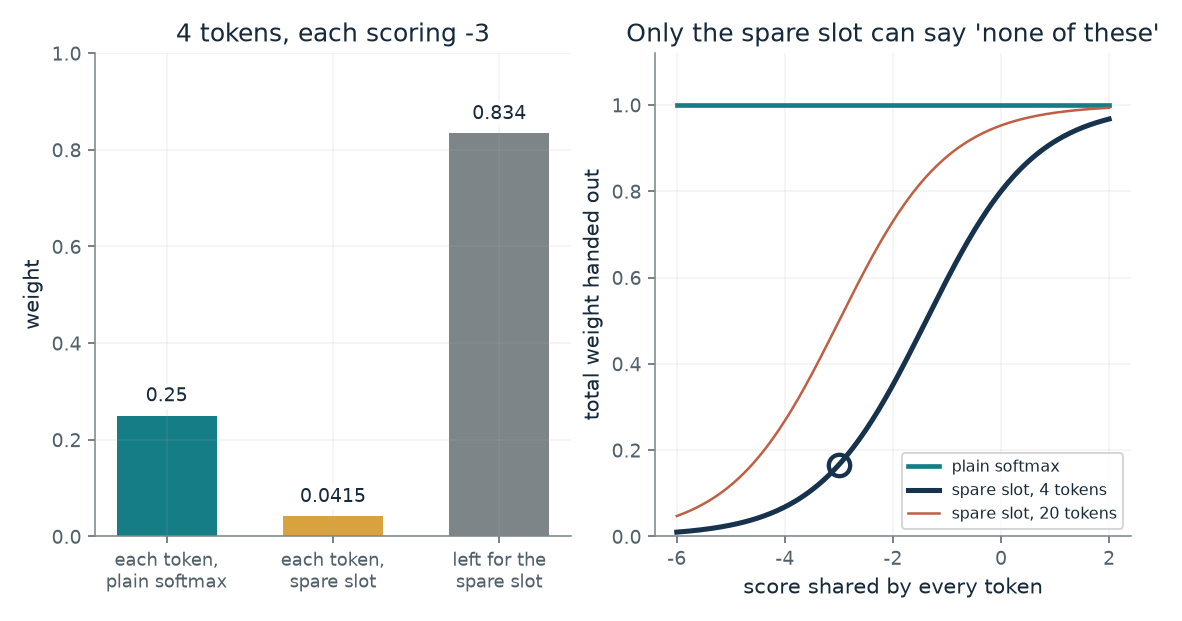

- **Each token, plain:** 0.25
- **Each token, spare slot:** 0.0415
- **Total, plain:** 1
- **Total, spare slot:** 0.166

Plain softmax gives each of 4 equal-scoring tokens 0.25 and always hands out a total of 1, whatever the score. With a spare slot each gets 0.0415 and the total is 0.166, which falls as the common score falls.

Plain: 1 / 4 = 0.25. Spare slot: e^(-3) / (1 + 4 e^(-3)) = 0.0415; total = 4 x 0.0415 = 0.166.

In [3]:
figure, values, explanation = spare_slot_picture(**{'score': -3, 'n_tokens': 4})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What changes when a head gets a spare slot?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Score shared by every token = -3, Number of tokens = 4: Plain softmax gives each token 0.25 and hands out 1 in all. With a spare slot each gets 0.0415 and the total is 0.166, about 0.17, leaving 0.834 for the slot that holds nothing. Raise the common score to 2 and the total rises to 0.967.

**Takeaway:** Plain softmax hands out a total of one however poor the scores, while a spare slot lets a head give nearly nothing when every score is low.

**Why it matters:** If every available score is equally poor, the weights alone do not say whether any available source is good. The same largest share could belong to an excellent passage in one search and the least unsuitable in another.

**In brains and behavior:** The cortex models in the next demonstration add a constant to the bottom of the division, which lets a weak input stay weak. Plain softmax has no such constant.

**In machines:** Xiao and colleagues found that a model reading long text with only its last 1,024 tokens scored a perplexity of 5,158 on one book, and 5.40 once the first four tokens were kept; they call such tokens attention sinks and attribute them to the sum-to-one rule, a claim they support with removal and restoration tests, not direct measurement. Miller proposed adding 1 to the denominator in 2023 without testing it, and in small models the idea helped only partly. OpenAI's gpt-oss models carry a learned spare slot in each head.

**Where it applies:** Equal scores, a spare slot that holds no value, and weights read as shares within one softmax, not as probabilities that a passage is true. The claim is about arithmetic and not a measurement of any trained model. A common score shift leaves plain softmax unchanged and changes the spare-slot weights unless the spare score is shifted too.

**Check your understanding:** Two tokens score 0 and 0. What does each get from plain softmax, and from a softmax with a spare slot, and what is the total?

<details><summary>Show the answer</summary>

Plain gives 0.5 each. With the spare slot each gets 1/3, and the total is 2/3.

</details>

*Source: Chapter 5, A model parked its spare weight on the first words. The chapter's constructed example (four tokens all scoring -3: a quarter each in plain softmax, about 0.04 each and about 0.17 in total with the extra 1) and the book's derivation 6 (scores 0 and 0: 0.5 each, or 0.333 each with a spare slot). The reported results are quoted in the sides and are from other people's studies, not recomputed here.*

## C05-D03: How does attention divide a response among rivals?

Two inputs compete for one response. What happens to each when attention boosts the weaker one?

Each response is its own boosted drive over the total boosted drive of everyone competing plus a constant. A strong rival raises the denominator and pushes its neighbors down, and attention boosts one numerator and the denominator together. The attended input therefore gains and each rival loses.

$$
R_i=\frac{g_i\,d_i}{\sigma+\sum_j g_j\,d_j}
$$

**Symbols:** R_i: response of cell i; d_i: its input drive, nonnegative (4 and 1 here); g_i: attention gain, above 1 for the attended input; sigma: a positive constant in the fitted model; 0 gives the softmax limit

**Predict before looking:** With no attention the responses are 2/3 and 1/6. Predict both responses when the second input gets a gain of 4 and sigma stays at 1.

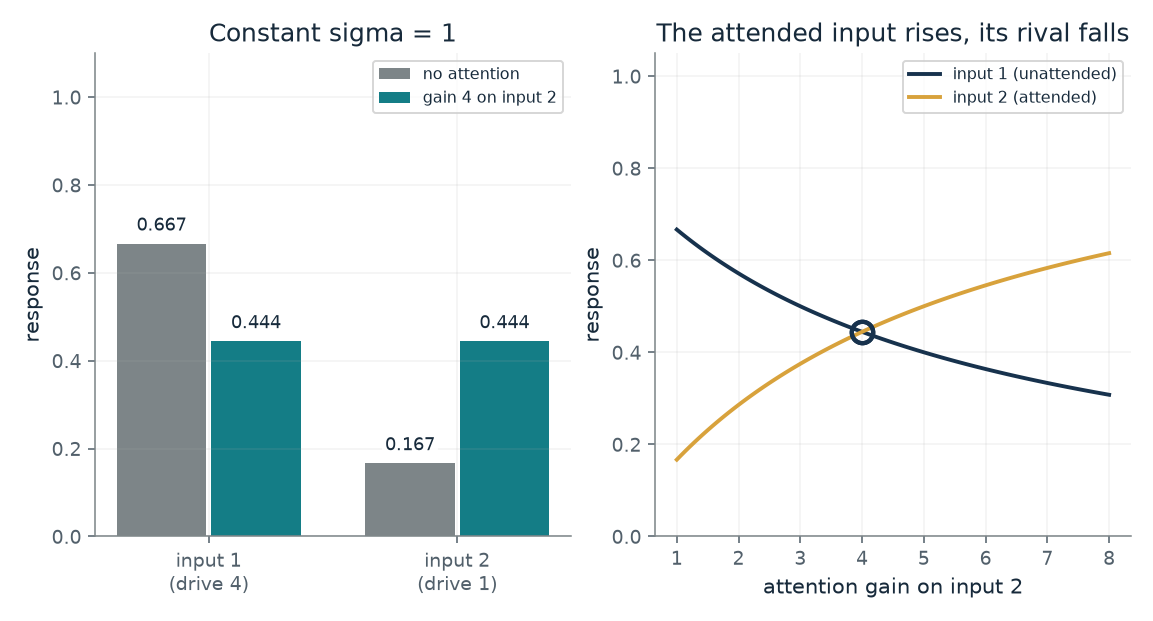

- **Response, input 1:** 0.444
- **Response, input 2:** 0.444
- **Sum of responses:** 0.889
- **Input 1 with no attention:** 0.667

With drives 4 and 1, constant 1 and a gain of 4 on input 2, the responses are 0.444 and 0.444, against 0.667 and 0.167 with no attention. The constant keeps the total below 1 and lets weak inputs stay weak.

Denominator = 1 + 4 + 4 x 1 = 9. R1 = 4 / 9 = 0.444; R2 = 4 / 9 = 0.444.

In [4]:
figure, values, explanation = normalization_picture(**{'gain': 4, 'sigma': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does attention divide a response among rivals?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Attention gain on input 2 = 4, Constant sigma = 1: Both responses become 4/9, about 0.444: the attended input rises from 0.167 and its rival falls from 0.667. With sigma 0 the pair would be 0.5 and 0.5 and would add to 1, the softmax limit.

**Takeaway:** A cue-driven gain boosts one input before the dividing, so the attended input rises and its rival falls, and the constant keeps the total below one so weak inputs stay weak.

**Why it matters:** This is the cortex-model counterpart of a softmax: the same dividing among rivals, with a constant that plain softmax lacks and a gain that comes from outside the inputs.

**In brains and behavior:** Reynolds and Heeger's model says attention multiplies a cell's input and the cell then divides by the total across its rivals. They call the model a mathematical abstraction, and the data identify no circuit.

**In machines:** Set sigma to zero, every gain to 1 and each drive to e raised to a score, and the formula is softmax. In a transformer the scores come out of the model's own comparison of positions, not from a cue or goal, so this is a mathematical correspondence and not evidence of a shared mechanism.

**Where it applies:** Nonnegative drives and gains. The sum runs over every rival, including the cell itself. The data identify no circuit, and here the gains come from outside the inputs, from a cue or a goal. With sigma 0 the formula is undefined only if every boosted drive is zero.

**Check your understanding:** Drives 4 and 1, sigma 1, gains 1 on both. What are the responses?

<details><summary>Show the answer</summary>

The denominator is 1 + 4 + 1 = 6, so the responses are 4/6 = 0.667 and 1/6 = 0.167.

</details>

*Source: Chapter 5, A monkey's cell and seven people fit a divided response. The chapter's worked numbers: drives 4 and 1, no attention, sigma 1 gives two thirds and one sixth, and a gain of 4 on the second input makes both four ninths. The formula simplifies Reynolds and Heeger's 2009 normalization model, which its authors call a mathematical abstraction.*

## C05-D04: How far did attention move a monkey's cell toward the attended bar?

One V4 cell fired 11.75 to a vertical bar, 17.80 to a tilted bar and 13.81 to both. How was the pair's response read, and what did attention do to the weights?

If the pair's response is a weighted average of the two single responses, the weight can be read off from where the pair falls between them. This cell's pair response is about a third of the way from the first to the second. Attention moved the fitted weight on the second bar from 0.55 to 0.74 when it was attended and to 0.34 when the first bar was.

$$
r_{\text{pair}}=(1-w)\,r_1+w\,r_2,\qquad w=\frac{r_{\text{pair}}-r_1}{r_2-r_1}
$$

**Symbols:** r_1, r_2: responses to the first and second bar alone, in spikes per second; r_pair: response to the two bars together; w: weight on the second bar; 0 gives it no share and 1 gives it the whole share; implied gain ratio: how much more gain on the second bar than at baseline would produce w, if w is a share g2 d2 / (g1 d1 + g2 d2); the companion's reading

**Predict before looking:** The cell fired 11.75 and 17.80 to the bars alone and 13.81 to both. Predict the weight on the tilted bar, and whether it is closer to 0, one third or 1.

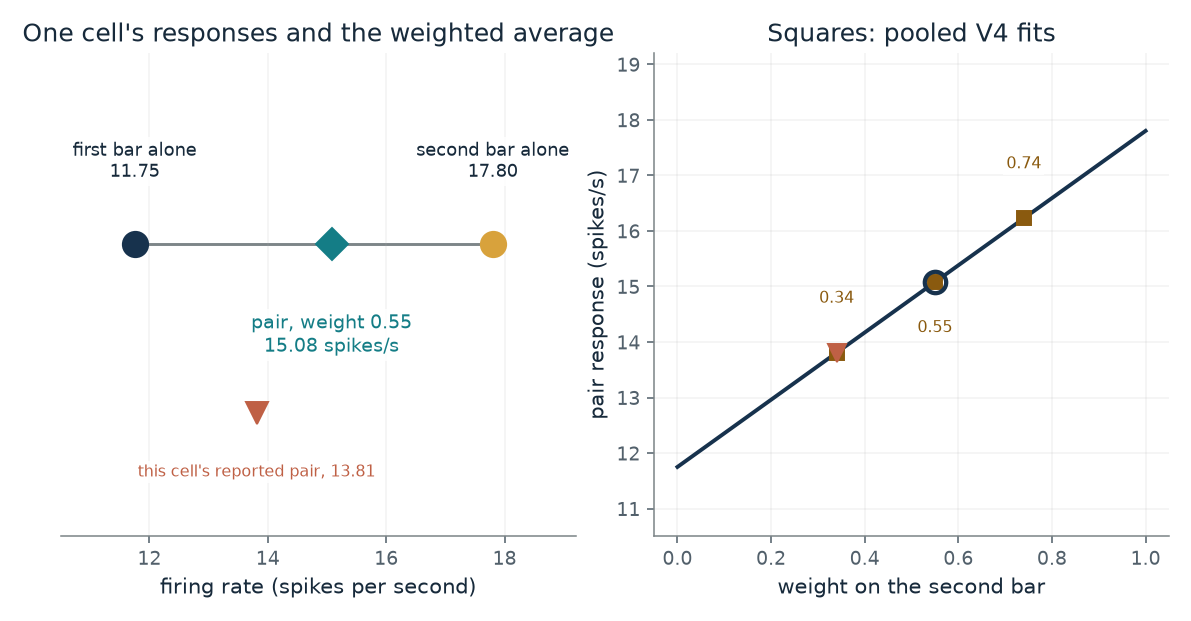

- **Pair response:** 15.08
- **Weight on second bar:** 0.55
- **This cell's own weight:** 0.34
- **Implied gain ratio:** 1

A weight of 0.55 on the second bar puts the pair at 15.08 spikes a second, between 11.75 and 17.80. The cell in the chapter fired 13.81, a weight of 0.34, about a third of the way.

Pair = (1 - 0.55) x 11.75 + 0.55 x 17.80 = 15.08. This cell: (13.81 - 11.75) / (17.80 - 11.75) = 0.34.

In [5]:
figure, values, explanation = weighted_average_picture(**{'weight': 0.55})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="How far did attention move a monkey's cell toward the attended bar?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on the second bar = 0.34: This cell's own weight is 0.34, about a third of the way from the vertical bar's response to the tilted bar's. At the pooled weight of 0.74 the pair would be at 16.23, and at 0.55 at 15.08, but these are the pooled weights applied to this cell's responses, not what this cell did.

**Takeaway:** Attention pulled the pair's response toward the attended bar's own response, as a weighted average whose weights shift with the attended location.

**Why it matters:** A response that behaves like a weighted average with shifting weights is the cortex-side picture of selection, and it can be compared with the weights a machine's head assigns.

**In brains and behavior:** The study recorded in V2 and V4 of three rhesus monkeys. The shifts the paper highlights are larger because they come from the cells that changed significantly, and no person was recorded.

**In machines:** A weighted average of values, with weights that shift, is also what a head's blend of values is. That is a mathematical likeness and not evidence of a shared mechanism.

**Where it applies:** The pooled weights come from fits across the analyzed V4 pairs, and the fit can include an offset. Attention effects varied across cells. In about a quarter of the V4 pairs the second bar significantly changed the response, but no significant attention effect was detected. Three monkeys; no person was recorded and no machine is involved.

**Check your understanding:** A cell fires 10 to bar A alone and 20 to bar B alone. With a weight of 0.3 on B, what does the pair fire?

<details><summary>Show the answer</summary>

0.7 x 10 + 0.3 x 20 = 13 spikes per second.

</details>

*Source: Chapter 5, A monkey's cell and seven people fit a divided response. Reynolds, Chelazzi and Desimone (1999) as the chapter reports it: one V4 cell's 11.75, 17.80 and 13.81 spikes per second, and pooled fitted weights on the second bar of about 0.55 with attention elsewhere, 0.74 with attention on the second bar and 0.34 with attention on the first. Applying the pooled weights to this one cell's responses is an illustration. The share rule is not in the paper.*

## C05-D05: Why does attention sometimes act like extra contrast and sometimes like a raised ceiling?

The normalization model predicts that attention can act like extra contrast or like a raised ceiling. How does one formula give both?

If the gain applies to every unit in the pool, it multiplies the numerator and the competing total together, which only rescales contrast. If it applies to the read-out unit alone, the competing total barely grows, so the ceiling rises with the gain.

$$
R=\frac{g\,c}{\sigma+c\,(k\,g+n-k)},\qquad \text{ceiling}=\frac{g}{k\,g+n-k},\qquad c_{50}=\frac{\sigma}{k\,g+n-k}
$$

**Symbols:** c: stimulus contrast, in units of sigma; g: attention gain on the attended units; k, n: units that receive the gain, and units in the competing pool (n = 8); c_50: the contrast giving half the ceiling; smaller means more sensitive

**Predict before looking:** With a gain of 4, predict which choice, covering 1 of the 8 pooled units or all 8, raises the ceiling of the response, and which only shifts its sensitivity.

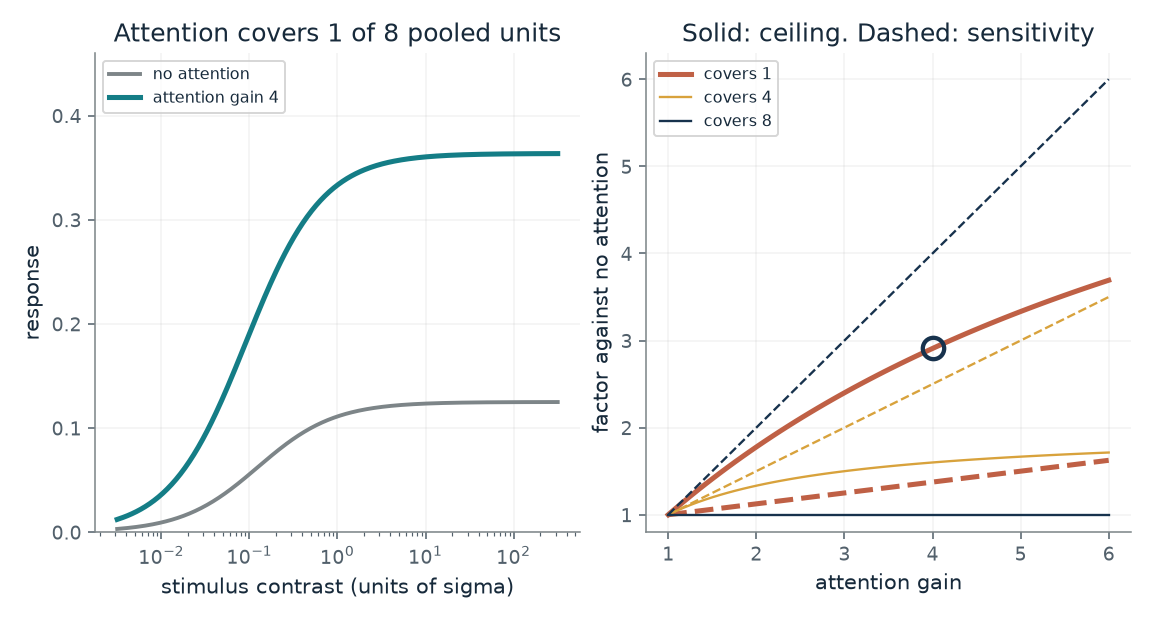

- **Ceiling with attention:** 0.364
- **Ceiling without:** 0.125
- **Ceiling factor:** 2.91
- **Sensitivity factor:** 1.38

With the attention gain 4 covering 1 of 8 pooled units, the ceiling goes from 0.125 to 0.364 and the sensitivity improves by a factor of 1.38. That is a raised ceiling with a smaller sensitivity change (response gain).

R = g c / (1 + c (k g + 8 - k)) with k = 1. Ceiling = g / (k g + 8 - k) = 0.364; half-response contrast = 1 / (k g + 8 - k) = 0.0909.

In [6]:
figure, values, explanation = gain_regime_picture(**{'gain': 4, 'covered': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does attention sometimes act like extra contrast and sometimes like a raised ceiling?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Attention gain = 4, Pooled units that get the gain (of 8) = 1: Covering only the unit itself raises the ceiling from 0.125 to 0.364, a factor of 2.9, and sensitivity by a smaller 1.38. Covering all 8 leaves the ceiling at 0.125 and makes the unit four times more sensitive: extra contrast.

**Takeaway:** The same attention gain looks like extra contrast when it covers everything that competes, and like a raised ceiling when it covers only part of it.

**Why it matters:** Whether attention helps most at faint or at strong stimuli depends on how its reach compares with the stimulus. Seven people's accuracy fit one gain passed through a broad or a narrow field.

**In brains and behavior:** Herrmann and colleagues tested the prediction in seven people. With large patches in fixed places attention raised accuracy at the highest contrasts, and with small patches in uncertain places it helped most at middling contrasts. It is a human behavior and imaging study and identifies no circuit.

**In machines:** A trained attention head has no such pool of units. This is a specification of cortex-style normalization, not a claim about transformers.

**Where it applies:** Equal drives across the pool, a gain on k units including the one read out, and a response that is a function of that unit's contrast alone. Accuracy is not modeled. In the human data, response-gain-only could not be rejected for endogenous attention, and the model identifies no circuit.

**Check your understanding:** A gain of 2 covers all 8 units and sigma is 1. What are the ceiling and half-response contrast with and without attention?

<details><summary>Show the answer</summary>

With every unit boosted, a = 2 x 8 = 16 and the ceiling is g / a = 2 / 16 = 0.125, the same as without attention (1 / 8). The half-response contrast falls from 1 / 8 = 0.125 to 1 / 16 = 0.0625: twice as sensitive.

</details>

*Source: Chapter 5, A monkey's cell and seven people fit a divided response. The chapter's formula R = g d / (sigma + sum g d), applied by the companion to a pool of n equally driven units of which k get the gain. The pool, k and the gains are made up. Using the share of the pool that attention covers in place of the comparison of stimulus size with the span of attention is a simplification; the model's actual stimulus and attention fields are spatial.*

## C05-D06: Why would look-alikes cost more than random passages?

If one passage holds the answer and the others score near it, how much of the weight does the answer keep?

Softmax compares the answer's exponential with the exponentials of the others. A passage with a score close to the answer's has an exponential close to the answer's and takes about as much weight. One far below has a tiny exponential and takes almost none, so random passages cost little and look-alikes cost much.

$$
\alpha_{\text{answer}}=\frac{e^{s_a}}{e^{s_a}+n\,e^{s_a-\Delta}}=\frac{1}{1+n\,e^{-\Delta}}
$$

**Symbols:** s_a: the answer passage's score; Delta: how far each other passage scores below the answer (0 for a tie); n: number of other passages (8 or 19 here); alpha_answer: the answer passage's share of the softmax weight

**Predict before looking:** Eight other passages score exactly as high as the answer. Predict the answer's share, and then its share when they score 4 below.

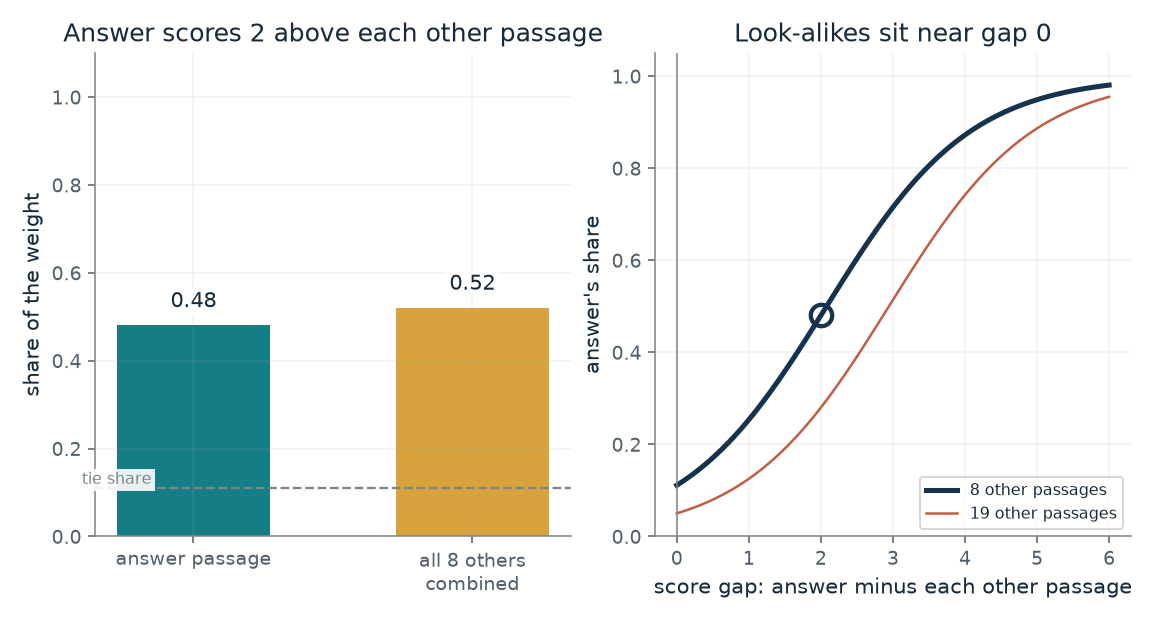

- **Answer passage's share:** 0.48
- **Others' combined share:** 0.52
- **Share if all tie:** 0.111
- **Each other passage:** 0.065

With 8 other passages each scoring 2 below the answer, the answer takes 0.48 of the weight and the others 0.52 together. A look-alike near gap 0 takes nearly as large a share as the answer; one far below takes almost none. This is softmax arithmetic, not a test of why models failed.

Answer share = 1 / (1 + 8 x e^(-2)) = 1 / (1 + 1.08) = 0.48.

In [7]:
figure, values, explanation = lookalike_picture(**{'gap': 2, 'n_distractors': 8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why would look-alikes cost more than random passages?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Score gap, answer minus each other passage = 0, Number of other passages = 8: With a tie the answer passage takes 1/9 = 0.111, the same as every other passage. At a gap of 4 it takes 0.872, and at a gap of 2 about 0.48. A look-alike near gap 0 takes nearly as large a share as the answer; one far below takes almost none.

**Takeaway:** Passages that score close to the answer take shares nearly as large as its own, so a crowd of look-alikes dilutes the answer far more than the same number of unrelated passages.

**Why it matters:** A weight is a share, and a share is relative to whatever else is present. The same largest share could belong to an excellent passage in one search and the least unsuitable one in another.

**In brains and behavior:** In Alexander and Zelinsky's search task, 24 students looked for a teddy bear or a butterfly among six pictures. When no picture was the target, search took 1.48 seconds if all six looked like it and 0.84 if none did, with 3.16 pictures looked at against 1.51; errors stayed under 6 percent. The costs were time and eye movements, not accuracy.

**In machines:** Cuconasu and colleagues added eight passages to an answer passage for four small open models. In all 12 combinations of model and position, eight look-alikes cost more accuracy than eight random passages. For Llama2 with the answer near the question, accuracy was 56.4 percent alone, 56.1 with random passages and 37.5 with look-alikes.

**Where it applies:** All other passages share one score gap, and the weight is a share within one softmax that ignores other heads, layers and operations. Cuconasu and colleagues did not test this explanation, and a look-alike passage may hold a plausible wrong answer, which the paper does not separate from taking attention.

**Check your understanding:** The answer passage scores 2 above each of 8 other passages. What share of the weight does it get?

<details><summary>Show the answer</summary>

1 / (1 + 8 e^-2) = 1 / (1 + 1.083) = 0.48, so the answer keeps a little under half.

</details>

*Source: Chapter 5, In 2023, facts in the middle of long prompts fared worst; look-alikes cost most. The chapter's remark that softmax arithmetic suggests why look-alikes would hurt: a passage that scores close to the answer takes a share nearly as large, while one that scores far below takes almost none. The score gaps are made up. The reported results in the sides are from Alexander and Zelinsky (2011) and Cuconasu and colleagues (2024), and are not recomputed.*

## C05-D07: Where in a long prompt did the answer fare worst?

A model answered 75.8 percent of questions when the answer passage came first among 20 and 53.8 when it came tenth. How large are those gaps against having no passages at all?

The comparison that matters is not only first against last but each position against the score with no passages at all. Being worse than no passages means the added text hurt more than it helped at that position. The rough band shows that differences of a point or two are small next to the sampling noise of 2,655 questions.

$$
\text{gap}=A_{\text{position}}-A_{\text{no passages}},\qquad \text{band}=1.96\sqrt{\frac{p(1-p)}{N}}
$$

**Symbols:** A: percent of questions answered correctly; gap: points above (positive) or below (negative) the no-passage score of 56.1 percent; N: number of questions, 2,655; band: a rough plus-or-minus range, the companion's own arithmetic, in points

**Predict before looking:** Predict which of the five positions was worst, and whether it fell below the score with no passages at all.

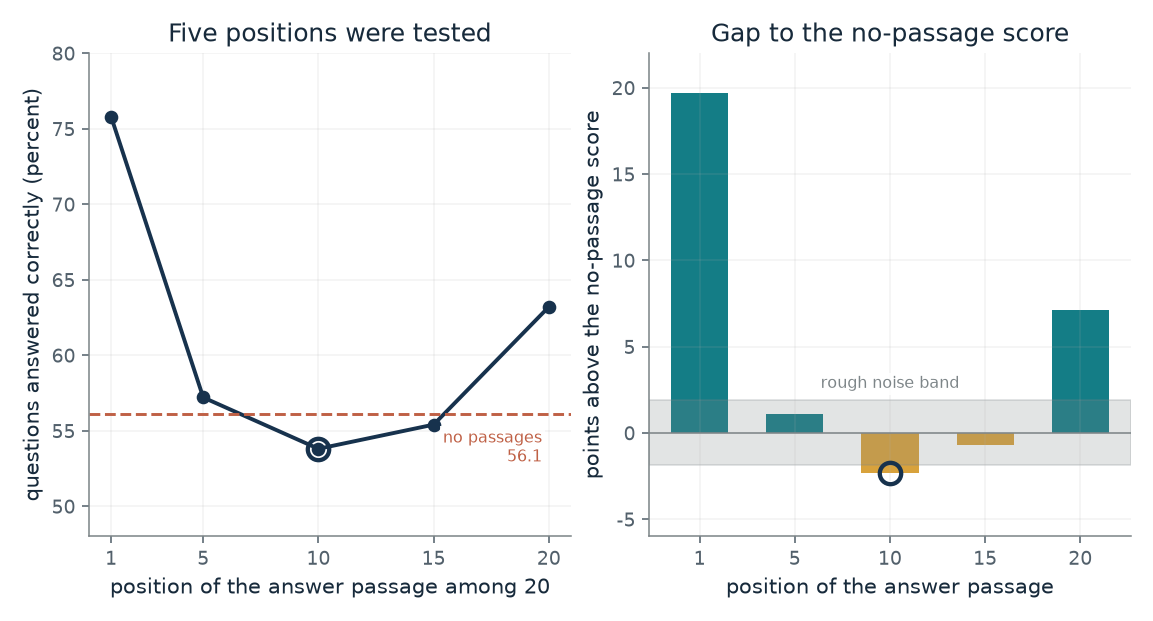

- **Accuracy at this position:** 53.8 percent
- **Points above no passages:** -2.3
- **Rough noise band (plus or minus):** 1.89
- **Gap outside the rough band:** yes

With the answer at position 10, the model answered 53.8 percent, 2.3 points below its no-passage score of 56.1. Only five positions were tested, so the curve between them is unknown, and the study measured answers, not attention weights.

Gap = 53.8 - 56.1 = -2.3 points. Rough band = 1.96 x sqrt(p(1 - p) / 2,655) x 100 = plus or minus 1.89 points for p = 0.561, ignoring that the same questions were used every time.

In [8]:
figure, values, explanation = lost_in_middle_picture(**{'position': 10, 'band': 'show'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Where in a long prompt did the answer fare worst?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Position of the answer passage = 10, Rough noise band = show: At the tenth position accuracy was 53.8 percent, 2.3 points below the 56.1 with no passages, while the first position was 19.7 points above and the last 7.1 above. The fifth and fifteenth are within about a point of the no-passage line, inside the rough band.

**Takeaway:** Answers were best when the passage came first, next best last and worst in the middle, where they fell slightly below having no passages at all; but only five positions were tested.

**Why it matters:** A long prompt does not give every position the same treatment, so where a fact sits can matter. The result shows that position can matter, not that it matters equally for every model.

**In brains and behavior:** The authors note the U shape resembles a pattern in human memory for lists, but the paper ran no human experiment.

**In machines:** GPT-3.5-Turbo (0613), one model tested in 2023. They measured answers, not attention weights, so nothing here ties the dip to attention sinks.

**Where it applies:** One model tested in 2023 at five positions, so the curve between them is unknown. The study measured answers, not attention weights, and established no single cause; the authors offered only hypotheses, and the crowd of look-alikes is a second suspect. The band treats each score as the share correct among 2,655 independent questions, but the same questions were used every time, so a paired comparison can be tighter or wider.

**Check your understanding:** Compute the gap to the no-passage score at the first position and at the tenth.

<details><summary>Show the answer</summary>

First: 75.8 - 56.1 = 19.7 points above. Tenth: 53.8 - 56.1 = -2.3, so 2.3 points below.

</details>

*Source: Chapter 5, In 2023, facts in the middle of long prompts fared worst; look-alikes cost most. Liu and colleagues' 2023 test of GPT-3.5-Turbo (0613) as the chapter reports it: 2,655 questions, 20 passages, one holding the answer and 19 look-alikes; 75.8, 57.2, 53.8, 55.4 and 63.2 percent at positions 1, 5, 10, 15 and 20, and 56.1 with no passages. The noise band is the companion's arithmetic, not a result from the chapter or the study.*

## Bring it to your own question

Ask what is being weighed, what each score or drive is, whether anything can give weight to nothing, and who supplies the gain: a cue or goal in the cortex models, the model's own comparison in a transformer. Use the softmax card for shares of a budget of one, the spare-slot card to see what changes when 'none of these' is allowed, the normalization card for gains and a constant, and the reported-result cards for position and look-alike effects. Say that a weight is a share, not a probability of truth.

Use the `mmi-ch05-what-to-notice` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.